## Imports

In [6]:
import importlib
import torch
import numpy as np
import Diffusion
import LossFunctions
import ConsistencyModels
import  FlowMatching
from ConsistencyModels import ConsistencyModel

importlib.reload(Diffusion)
importlib.reload(LossFunctions)
importlib.reload(ConsistencyModels)
importlib.reload(FlowMatching)


<module 'FlowMatching' from 'C:\\Users\\orine\\PycharmProjects\\finalThesis\\FlowMatching.py'>

## Sample Data

In [7]:
import torch
import numpy as np
from scipy.optimize import fsolve
import torch.nn.functional as F

def sample_gumbel(shape, eps=1e-10):
    U = torch.rand(shape, dtype=torch.float64)
    return -torch.log(-torch.log(U + eps) + eps)

def gumbel_softmax_sample(logits, tau=1.0):
    gumbel_noise = sample_gumbel(logits.shape)
    y = logits + gumbel_noise
    return F.softmax(y / tau, dim=-1)

def sample_univariate_gaussian(mean, variance):
    """
    Sample from univariate Gaussian using reparameterization trick

    Args:
        mean: tensor of shape [1] or scalar
        variance: tensor of shape [1] or scalar

    Returns:
        sample: tensor of shape [1]
    """
    std = torch.sqrt(variance).squeeze()
    epsilon = torch.randn(1, dtype=mean.dtype)
    return mean.squeeze() + std * epsilon

def sample_multivariate_gaussian(mean, covariance):
    """
    Sample from multivariate Gaussian using reparameterization trick

    Args:
        mean: tensor of shape [D]
        covariance: tensor of shape [D, D]

    Returns:
        sample: tensor of shape [D]
    """
    # Ensure covariance matrix is positive definite
    eps = 1e-6 * torch.eye(covariance.size(0), dtype=covariance.dtype)
    L = torch.linalg.cholesky(covariance + eps)

    # Generate standard normal noise
    epsilon = torch.randn(mean.size(), dtype=mean.dtype)

    # Apply reparameterization trick
    return mean + torch.matmul(L, epsilon)

def generate_mog_samples(n_samples, xi, S, beta, tau=7.5):
    """
    Generate samples from mixture of Gaussians using reparameterization trick

    Args:
        n_samples: number of samples to generate
        xi: list of means (each can be scalar or vector)
        S: list of variances/covariance matrices
        beta: mixture weights
        tau: temperature for Gumbel-Softmax
    """
    # Ensure xi and S are tensors
    if isinstance(xi, list):
        xi = torch.stack(xi)
    if isinstance(S, list):
        S = torch.stack(S)

    # Get dimensions
    is_multivariate = len(xi.shape) > 1 and xi.shape[-1] > 1

    # Compute logits from beta
    logits = torch.log(beta)

    # Sample component assignments using Gumbel-Softmax
    component_weights = gumbel_softmax_sample(logits, tau)

    # Sample component indices
    component_idx = torch.multinomial(component_weights, n_samples, replacement=True)
    means = xi[component_idx]
    vars_or_covs = S[component_idx]

    # Generate samples using appropriate sampling function
    samples = []
    for mean, var_or_cov in zip(means, vars_or_covs):
        if is_multivariate:
            sample = sample_multivariate_gaussian(mean, var_or_cov)
        else:
            sample = sample_univariate_gaussian(mean, var_or_cov)
        samples.append(sample)

    samples = torch.stack(samples)
    return samples


In [8]:
mu_list = [np.array([-5, 4]),
           np.array([5, -4]),
           # np.array([3, 5]),np.array([-1, 5]), np.array([0, 0]), np.array([5, -1]),np.array([-5, -1]), np.array([2, 1]),np.array([1, -7])
           ]

point_l = [[int(p[1]), int(p[0])] for p in mu_list]

mu_list = [torch.tensor(p, dtype=torch.float64) for p in point_l]

# Convert Sigma_list to 3D covariance matrices
Sigma_list = [
    torch.tensor([[2,0.12],[0.12,0.5]], dtype=torch.float64)
] * len(mu_list)

# Mixture weights
alpha =torch.tensor( [1 / len(mu_list)] * len(mu_list),dtype=torch.float64)
# Generate samples
device = 'cpu'  # Change to 'cuda' if using a GPU
# X = dist_utils.generate_mog_samples(n_samples, mu_list, Sigma_list, alpha )


mog_means = [
    torch.tensor([5.0], dtype=torch.float64),
    # torch.tensor([-5.0], dtype=torch.float64),

]
mog_variances = [torch.tensor([.25], dtype=torch.float64),
     # torch.tensor([.25], dtype=torch.float64),
     ]
weights = torch.tensor([1.,
                        # .5
                        ], dtype=torch.float64)


In [9]:
X = generate_mog_samples(50_000, mu_list, Sigma_list, alpha).float().to(device)

In [10]:
STOP STOP ASDASDASDSADASD

SyntaxError: invalid syntax (2697973423.py, line 1)

## Diffusion Model

### Regular

In [ ]:
nfeatures= X.shape[1]
model_diff = Diffusion.DiffusionModel(nfeatures=nfeatures, nunits=128*2, condition=False,condition_on=1,nblocks=3)
losses = model_diff.train_model(X, nepochs=100, batch_size=2048,condition_on=1)

In [ ]:
model_diff.eval()

gen_samples,_=model_diff.sample_ddim( 1_000, condition_x=None, device="cpu", eta=0.0, t_start=None, t_end=None)
gen_samples=gen_samples.detach().numpy()

In [ ]:
import matplotlib.pyplot as plt
import torch
X_cpu = X.cpu()
plt.figure(figsize=(8, 8))
plt.scatter(X_cpu[:, 0], X_cpu[:, 1], color="blue", alpha=0.5, label="Real", s=10)
plt.scatter(gen_samples[:, 0], gen_samples[:, 1], color="red", alpha=0.5, label="Generated", s=10)
plt.title(f"Real vs Generated Samples ")
plt.xlabel("x1")
plt.ylabel("x2")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
STOP HERE

### Conditional

In [ ]:
# nfeatures= X.shape[1]
# model_cond_diff =Diffusion.DiffusionModel(nfeatures=nfeatures, nblocks=4, nunits=128, condition=True,condition_on=1)
# losses = model_cond_diff.train_model(X, nepochs=100, batch_size=3*2048,condition_on=1)

In [ ]:
# model_cond_diff.eval()
# condition= torch.tensor([5.]).view(1, -1).repeat(1_000, 1)
# gen_samples,_=model_cond_diff.sample_ddim( 1_000, condition_x=condition, device="cpu", eta=0.0, t_start=None, t_end=None)
# gen_samples=gen_samples.detach().numpy()

In [ ]:
# import matplotlib.pyplot as plt
# import torch
# X_cpu = X.cpu()
# plt.figure(figsize=(8, 8))
# plt.scatter(X_cpu[:, 0], X_cpu[:, 1], color="blue", alpha=0.5, label="Real", s=10)
# plt.scatter(gen_samples[:, 0], gen_samples[:, 1], color="red", alpha=0.5, label="Generated", s=10)
# plt.title(f"Real vs Generated Samples ")
# plt.xlabel("x1")
# plt.ylabel("x2")
# plt.legend()
# plt.grid(True)
# plt.tight_layout()
# plt.show()

In [ ]:
# STOP BREAK SADASD;LAKSD;AKSDA

## MMD

In [ ]:
# import torch
#
# # Create two vectors: one from N(0, 1), another from N(10, 1)
# a = torch.randn(100, 1)              # Mean 0, Std 1
# b = torch.randn(100, 1) + 10         # Mean 10, Std 1
#
# # Initialize MMD loss with default RBF kernel
# mmd_loss = LossFunctions.MMDLoss(kernel=LossFunctions.RBF())
#
# # Compute the MMD loss
# loss = mmd_loss(a, b)
#
# print("MMD Loss between N(0,1) and N(10,1):", loss.item())


## Consistency Models

### Regular

In [ ]:
import matplotlib.pyplot as plt
import torch

def sample_and_plot(model, X, name="mog", device="cpu", steps=[80.0, 40.0, 20.0, 10.0, 5.0],n_samples=5_000):
    """
    Sample from the model and plot both the real (X) and generated samples in 2D.
    Assumes X.shape[1] == 2.
    """
    assert X.shape[1] == 2, "This function only supports 2D data for plotting."

    # model.eval()
    with torch.no_grad():
        z = torch.randn(n_samples,X.shape[1])*steps[0]
        xh = model.sample(z, steps).cpu()

    X_cpu = X.cpu()

    plt.figure(figsize=(8, 8))
    plt.scatter(X_cpu[:, 0], X_cpu[:, 1], color="blue", alpha=0.5, label="Real", s=10)
    plt.scatter(xh[:, 0], xh[:, 1], color="red", alpha=0.5, label="Generated", s=10)
    plt.title(f"Real vs Generated Samples ({name})")
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    # plt.savefig(f"./contents/ct_{name}_scatter.png")
    plt.show()


In [ ]:
n=50_000

X = generate_mog_samples(n, mu_list, Sigma_list, alpha).float().to(device)

In [ ]:
condition=0
B, C = X.shape
D = 128
input_dim = C - condition
cond_dim = condition
Cos_model = ConsistencyModel(input_dim=input_dim, cond_dim=cond_dim, D=D)
# model=train_consistency(Cos_model,X, n_epoch=100, device=device, name="mog",condition=0)

In [ ]:
Cos_model.train_model(X=X, n_epoch= 100, device= "cpu", condition=0)


In [ ]:
sample_and_plot(Cos_model, X, name="mog", device="cpu", steps=[50.,10.,5.,2.])

In [ ]:
!!asdasiodpasdopaispdoa

### Conditional

In [ ]:
condition=1
B, C = X.shape
D = 128
input_dim = C - condition
cond_dim = condition
Cos_model = ConsistencyModel(input_dim= input_dim, cond_dim=cond_dim, D=D)

In [ ]:
Cos_model.train_model(X=X, n_epoch= 100, device= "cpu", condition=1)

In [ ]:
# model=train_consistency(Cos_model,X, n_epoch=100, device=device, name="mog",condition=1)

In [ ]:
steps=[80.0, 40.0, 20.0, 10.0, 5.0,1.]
Cos_model.eval()
with torch.no_grad():
    z = torch.randn(1000,1)*steps[0]
    xh = Cos_model.sample(z, steps,cond=torch.tensor([5.]).repeat(1000,1)).cpu()

In [ ]:
import matplotlib.pyplot as plt

# Assuming xh is a torch tensor
xh_cpu = xh.detach().cpu().numpy()

plt.hist(xh_cpu, bins=50)  # You can adjust number of bins
plt.title("Histogram of xh")
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.show()


## FM

### Regular

In [ ]:
### Regular
input_dim = 2  #4mog_means[0].shape[0]
y_dim = 0  #mu_list[0].shape[0] - input_dim
hidden_dim = 256
depth = 4


In [28]:

# init flow
vf_x_y = FlowMatching.FMModel(input_dim=input_dim,
                                   time_dim=1,
                                   y_dim=y_dim,
                                   hidden_dim=hidden_dim,
                                   depth=depth,
                                   device=device)  # train

vf_x_y.train_FM(lr=0.001, batch_size=1024, print_every=20000,
                     X=X, nepochs=1)


loss: 6.742557: 100%|██████████| 1/1 [00:07<00:00,  7.10s/it]


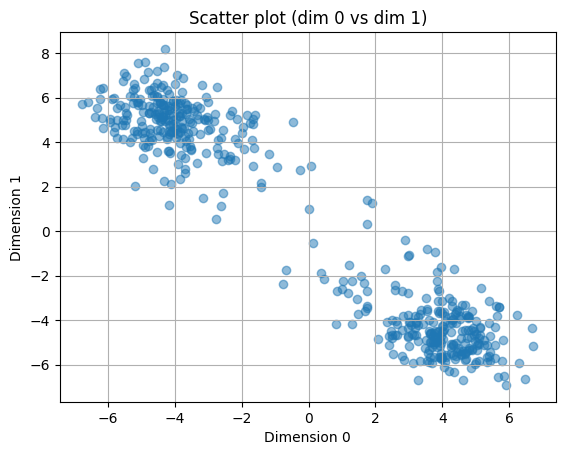

In [29]:
import matplotlib.pyplot as plt

xh_cpu = vf_x_y.sample(500).detach().cpu().numpy()
plt.scatter(xh_cpu[:, 0], xh_cpu[:, 1], alpha=0.5)  # or [:, 0] vs [:, 2], etc.
plt.title("Scatter plot (dim 0 vs dim 1)")
plt.xlabel("Dimension 0")
plt.ylabel("Dimension 1")
plt.grid(True)
plt.show()

### Conditional

In [15]:
input_dim = mog_means[0].shape[0]
y_dim = mu_list[0].shape[0] - input_dim
hidden_dim=256
depth=4


In [16]:
vf_y_cond_x.train_FM(lr=0.001, batch_size=1024, print_every=20000,
             X=X, nepochs=100)

  0%|          | 0/100 [00:00<?, ?it/s]


KeyboardInterrupt: 

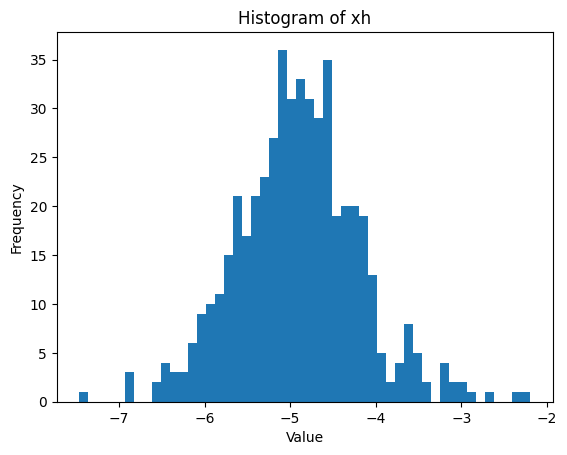

In [8]:
import matplotlib.pyplot as plt

xh_cpu=vf_y_cond_x.sample(500,torch.tensor([5.])).detach().cpu().numpy()

plt.hist(xh_cpu, bins=50)  # You can adjust number of bins
plt.title("Histogram of xh")
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.show()